# Rydberg Gate Error Budget

Python companion to the AMO Toolkit page [Rydberg Gate Error Budget](https://amotoolkit.com/pages/fidelity-budget.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/fidelity-budget.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Eight error sources, added linearly
The page's budget for a Rydberg CZ gate of duration t:

| source | estimate |
|---|---|
| spontaneous emission | Γ<sub>Ryd</sub> t, with τ = τ₀ n*³ (halved at 300 K for blackbody radiation) |
| Doppler dephasing | ½ (k v<sub>rms</sub> t)², v<sub>rms</sub> = √(k<sub>B</sub>T/m) |
| laser phase noise | π Δν t |
| blockade leakage | (Ω/U)² |
| SPAM | as entered |
| atom loss | t / τ<sub>trap</sub> |
| magnetic dephasing | ½ (μ<sub>B</sub> ΔB t/ħ)² |
| Rabi inhomogeneity | ½ (π δΩ/2Ω)² |

**Read with care:** k is that of a single photon at the Rydberg wavelength; a two-photon scheme with counter-propagating beams has a smaller effective k and a much smaller Doppler term. The errors are added, which is only right while each is small.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

kB, hbar, muB, amu = 1.380649e-23, 1.054572e-34, 9.274010e-24, 1.660539e-27
ATOMS = {   # mass (u), τ0 (ns), single-photon Rydberg λ (nm), quantum defect δ0 (nS)
    "Rb87": (86.909, 1.43, 480, 3.131), "Cs133": (132.905, 1.80, 510, 4.049),
    "Yb171": (170.936, 2.00, 302, 4.279), "Sr88": (87.906, 1.80, 317, 3.269),
}

def budget(species="Rb87", n=60, t_gate_us=10**0.3, T_uK=5, room_temp=True, linewidth_kHz=1.0,
           U_over_Omega=50, spam_pct=0.5, tau_trap_s=10, dB_mG=1.0, dOmega_pct=1.0):
    m_u, tau0, lam, d0 = ATOMS[species]
    t = t_gate_us * 1e-6
    tau_us = tau0 * 1e-3 * (n - d0) ** 3 / (2 if room_temp else 1)
    k = 2 * np.pi / (lam * 1e-9)
    v = np.sqrt(kB * T_uK * 1e-6 / (m_u * amu))
    eps = {
        "Spont. emission": 1e6 / tau_us * t,
        "Doppler (thermal)": 0.5 * (k * v * t) ** 2,
        "Laser phase noise": np.pi * linewidth_kHz * 1e3 * t,
        "Blockade leakage": 1 / U_over_Omega**2,
        "SPAM": spam_pct / 100,
        "Atom loss": t / tau_trap_s,
        "B-field dephasing": 0.5 * (muB * dB_mG * 1e-7 * t / hbar) ** 2,
        "Rabi inhomogeneity": 0.5 * (np.pi * dOmega_pct / 100 / 2) ** 2,
    }
    return eps, tau_us

eps, tau = budget()      # the page's defaults (t_gate = 2 µs)
total = sum(eps.values())
print(f"Rydberg lifetime {tau:.0f} µs; total error {total:.3e}; fidelity {100*(1-total):.3f}%\n")
for k_, v_ in sorted(eps.items(), key=lambda x: -x[1]):
    print(f"{k_:>20}: {v_:.2e}  ({100*v_/total:5.1f}%)")

Rydberg lifetime 132 µs; total error 1.903e-01; fidelity 80.973%

   Doppler (thermal): 1.63e-01  ( 85.7%)
     Spont. emission: 1.52e-02  (  8.0%)
   Laser phase noise: 6.27e-03  (  3.3%)
                SPAM: 5.00e-03  (  2.6%)
    Blockade leakage: 4.00e-04  (  0.2%)
   B-field dephasing: 1.54e-04  (  0.1%)
  Rabi inhomogeneity: 1.23e-04  (  0.1%)
           Atom loss: 2.00e-07  (  0.0%)

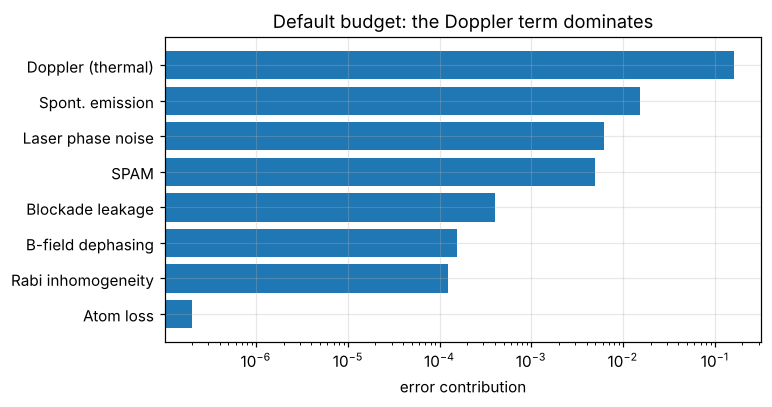

In [2]:
names = sorted(eps, key=eps.get)
plt.barh(names, [eps[k_] for k_ in names]); plt.xscale("log"); plt.xlabel("error contribution")
plt.title("Default budget: the Doppler term dominates")

## 2. What would it take?
A typical route to 99.5%: a shorter gate (faster Rabi frequency), colder atoms, and a narrower laser. (Course problem, week 12.)

In [3]:
for label, kw in [("defaults", {}),
                  ("t = 0.25 µs", dict(t_gate_us=0.25)),
                  ("+ T = 2 µK", dict(t_gate_us=0.25, T_uK=2)),
                  ("+ U/Ω = 100", dict(t_gate_us=0.25, T_uK=2, U_over_Omega=100)),
                  ("+ SPAM 0.1%", dict(t_gate_us=0.25, T_uK=2, U_over_Omega=100, spam_pct=0.1))]:
    e, _ = budget(**kw); s = sum(e.values())
    print(f"{label:>14}: F = {100*(1-s):.2f}%   dominant: {max(e, key=e.get)}")

      defaults: F = 80.97%   dominant: Doppler (thermal)
   t = 0.25 µs: F = 98.92%   dominant: SPAM
    + T = 2 µK: F = 99.08%   dominant: SPAM
   + U/Ω = 100: F = 99.11%   dominant: SPAM
   + SPAM 0.1%: F = 99.51%   dominant: Spont. emission

## 3. Check against the page

In [4]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(fidelity_pct=100 * (1 - total), tau_us=tau, total=total, doppler=eps["Doppler (thermal)"], spont=eps["Spont. emission"],
            phase=eps["Laser phase noise"], bfield=eps["B-field dephasing"], rabi=eps["Rabi inhomogeneity"])
DECIMALS = dict(fidelity_pct=3, tau_us=0)
page = dict(fidelity_pct=80.973, tau_us=132, total=1.903e-1, doppler=1.63e-1, spont=1.52e-2, phase=6.27e-3, bfield=1.54e-4, rabi=1.23e-4)
check(ours, page)

fidelity_pct: notebook 80.97        page 80.973     OK
      tau_us: notebook 131.5        page 132        OK
       total: notebook 0.1903       page 0.1903     OK
     doppler: notebook 0.1631       page 0.163      OK
       spont: notebook 0.01517      page 0.0152     OK
       phase: notebook 0.006268     page 0.00627    OK
      bfield: notebook 0.0001539    page 0.000154   OK
        rabi: notebook 0.0001234    page 0.000123   OK
All values match the page.